# 1. Регресиия
Регрессия - это зависимость среднего значения какой-либо велечины от некоторой другой величины или от нескольких других величин. В отличии от чисто функциональной зависимости $$y = f(x)$$, когда каждому значению независимой переменной ***x*** соотвествует одно определённое значение зависимой переменной одно определённое значение зависимой переменной *y*, при регресионной сязи одному и тому же значению независимой переменной(фактору) ***x*** могут соотвествовать в зависимости от конкретного случая различные занчения зависимосй переменной (отклика) ***y***.
Изучение регресии основано на том, что случайные величины ***X*** и ***Y*** связаны между собой вероятностной зависимостью: при каждом конкретном значении ***X = x*** величина ***Y*** является случайной величиной со вполне определённым распределием вероятностей. Зависимость зависимой переменной - отклика от одной независимой переменной - фактора или нескольких факторов называется урпавнением регресии. По количеству факторов выделяют парную выделяют парную (однофакторную) и множественную (многофакторную) регрессию. Для парной будет рассматривать следующие методы регресии: линейную, показательную, экспоненциальную, гиперболическую и параболическую. 

Регрессионный анализ - это раздел математической статистики, изучающих регрессионную зависимость между случайными величинами по статистическим данным. Цель регрисионного анализа состоит в опредлении общего вида уравнения регрессии, вычислении оценок неизвестных параметров, входящих в уравнение регрессии проверке статистических гипотез о регрессионной связи.

Таким образом, регрисионный анализ - набор статистических методов ислледования влияния одной или несколких независимых переменных ***X1,...,Xn*** на зависимую переменную ***Y***. Независимые переменные иначе называют регрессорами или предикторами, а зависимые переменные - критериальными переменными. 



## 1.1 Теоретический материал - Линейные регрессионные модели
Линейная регрессия (Linear regression) - модель зависимости перменной x от одной или нескольких других переменных (факторов, регрессоров, независимых переменных) с линейной функцией зависимости. Линейная регрессия относится к задаче определения "линиии наилучшего соотвествия" через набор точек данных и стала простым предшественником нелинейных методов, которые используются для обучения нейронных сетей. 

Цель линейной регресии - поиск линии, которая наилучшим образом соотвествует точкам. Напомним, что общее уравнение для прямой есть $f(x) = b + m * x$, где ***m*** - наклон линиии, а ***b*** - его сдвиг.

**Функция потерь - метод наименьших квадратов**
Функция потерь - это мера количества ошибок, которые наша линейная регрессия делает на наборе данных. Хотя есть разные функции потерь, все они вычисляют расстояние между предсказанным значением ***y(x)*** и его фактическим значением.
Одна очень распространенная функция потерь называется средней квадратичной ошибкой **MSE**. Чтобы вычислить - **MSE**, мы просто берем все значения ошибок, считаем их квадраты длин и усредняем.
**Задача экраполяции**
Допустим у нас есть много экспериментальных точек. Необходимо через них провести кривую, которая как можно ближе к этим точкам. При этом необходимо минимизировать среднюю квардратичную ошибку (**MSE**).
Для решения данной задачи в Python есть множество библиотек. Самым распространенным выступают:
```python
numpy - numpy.linalg.lstsq
scipy - scipy.linalg # Содержит все функции из numpy.linalg плюс часть новых функций, которых нет в numpy.linalg
```

### 1.1.1 Пример
***Задача:*** Проведем прямую $$ y = mx+b $$ через экспериментальные точки. 

0.9999999999999999 -0.9499999999999995


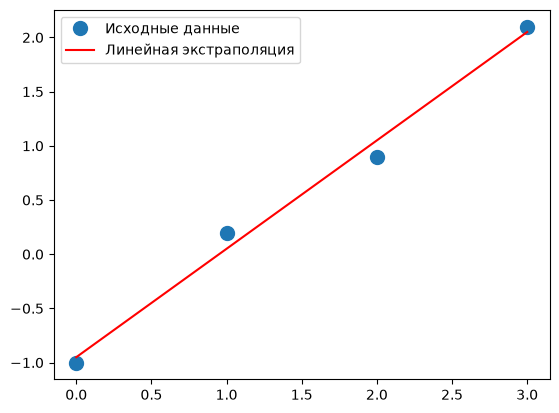

In [39]:
import numpy as np
x = np.array([0,1,2,3])
y = np.array([-1,0.2,0.9,2.1])

# Перепишем лиейное уравнение y = mx + c как y = Ap, где [[ x 1 ]] и p = [[m], [c]]
# Построим A по x:

A = np.vstack([x, np.ones(len(x))]).T
m,c = np.linalg.lstsq(A, y, rcond = None)[0]
print(m,c)

import matplotlib.pyplot as plt
plt.plot(x,y,'o',label='Исходные данные', markersize=10)
plt.plot(x,m*x+c,'r',label='Линейная экстраполяция')
plt.legend()
plt.show()

### 1.1.2 Пример
***Задача:*** Путь *x,y* - вектрона длиной *n>3* (точек > 3). Задача заключается в построении экстраполяционного полинома второго порядка (параболы)ю Таким образом, необходимо найти такие коэффиценты полином *a,b,c* по методу наименьших квадратов. Данные могут быть получены в результате измерений. Покажем пример генерации данных случайным образом и загрузки их из файла.

[-4.81985604 -4.46025805 -3.23002037 -1.89399207 -0.51304983  0.44637907
  1.28988775  2.34321179  3.06713794  4.47852545  5.34987385]
[24.96520734 15.65397037  9.38099962  3.528473    0.53368311 -0.21697206
  1.37641284  3.534875    8.78841718 15.89925247 24.57515735]


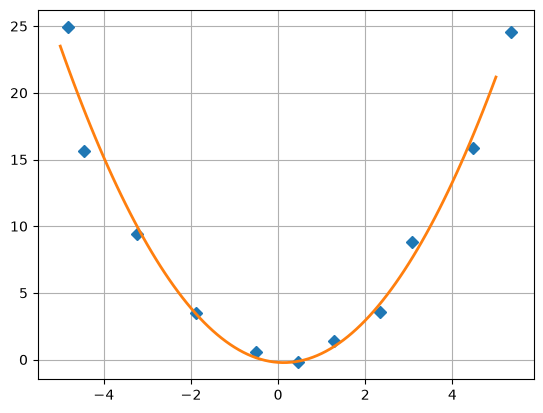

In [40]:
from numpy import *
from numpy.random import *
#генерируем случайные x и y
delta = 1.0
x = linspace(-5, 5, 11)
y = x**2+delta*(rand(11)-0.5)
x += delta*(rand(11)-0.5)

# записываем данные в файл
x.tofile('x_data.txt', '\n')
y.tofile('y_data.txt', '\n')

# читаем данные из файлов
x = fromfile('x_data.txt', float, sep='\n')
y = fromfile('y_data.txt', float, sep='\n')

print(x)
print(y)

# Нахождение коэффицентов функции вида y = ax^2 + bx +c методом наименьших квадратов
# задаем вектор m = [x**2, x, E]
m = vstack((x**2, x, ones(11))).T
# находим коэффиценты при составляющих вектор m
s = np.linalg.lstsq(m, y, rcond = None)[0]

# на отрезке [-5,5]
x_prec = linspace(-5,5,101)
# рисуем точки
plt.plot(x, y, 'D')
# рисуем кривую вида y = ax^2 + bx +c, подставляя из решения коэффиценты s[0], s[1], s[2]
plt.plot(x_prec, s[0] * x_prec**2 + s[1] * x_prec+s[2],'-',lw=2)
plt.grid()
plt.savefig('парабола.png')

### 1.1.3 Пример
***Задача:*** по данным предыдущего примера постройте экстраполяцию полинома третьего порядка

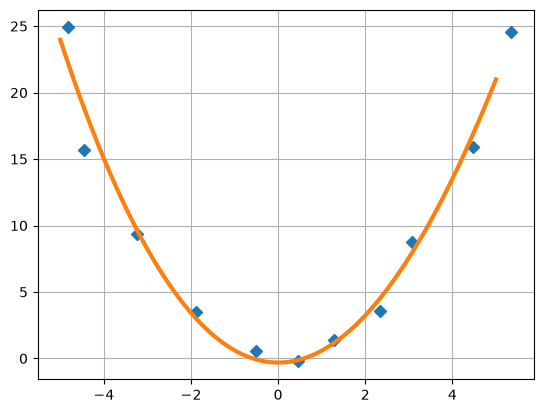

In [41]:
# Нахождение коэффицентов функции вида y = ax^3 + bx^2 + cx + d методом наименьших квадратов
# задаем вектор m = [x**3, x, E]
m = vstack((x**3, x**2, x, ones(11))).T
# находим коэффиценты при составляющих вектора m
s = np.linalg.lstsq(m, y, rcond = None)[0]

# на отрезке [-5,5]
x_prec = linspace(-5, 5, 101)
# рисуем точки
plt.plot(x, y, 'D')
# рисуем кривую вида y = ax^3 + bx^2 + cx +d, поставляя из решения коэфиценты s[0], s[1], s[2], s[3]
plt.plot(x_prec, s[0] * x_prec**3 + s[1] * x_prec**2 + s[2]*x_prec + s[3],'-',lw=3 )
plt.grid()
plt.savefig('полином 3-й степени.png')  


***Задание:*** представьте собственне данные и постройте экстраполяцию полиномами первой, второй и третьей степени.

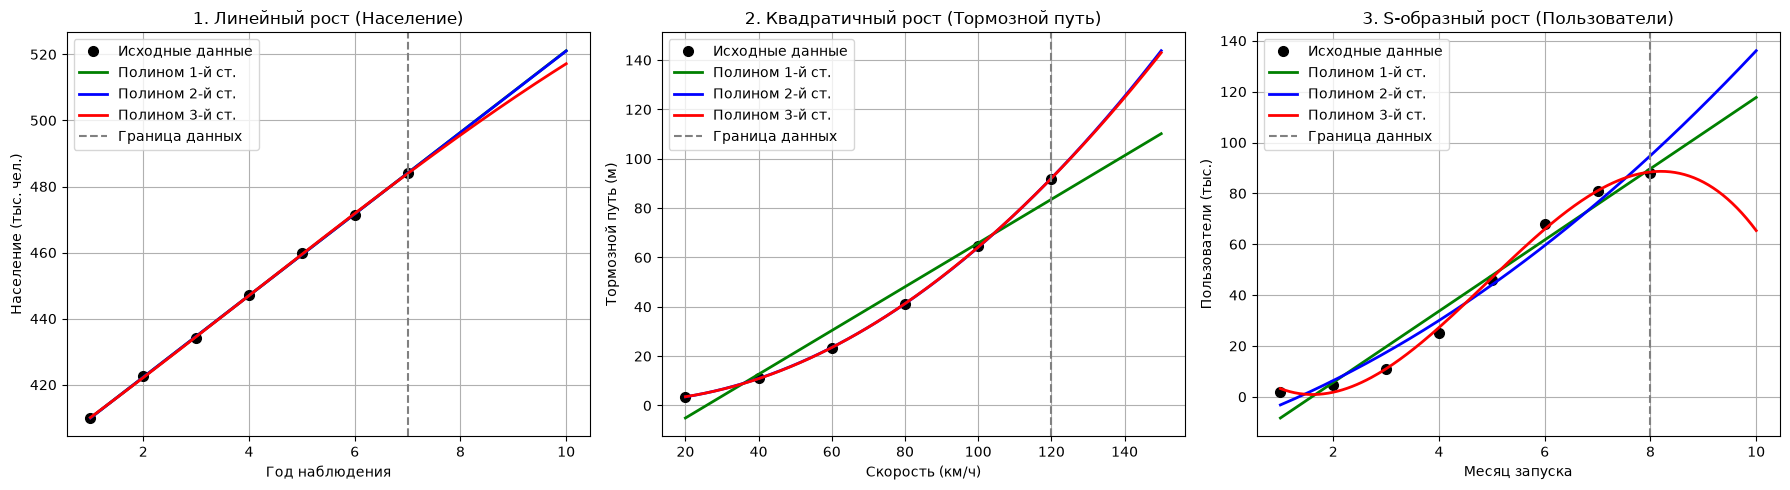

In [42]:
import matplotlib.pyplot as plt
import numpy as np

# Задаем примеры данных
datasets = [
    #  Зависимости населения города от года проведенной переписи (лийеный рост)
    {
        'title': '1. Линейный рост (Население)',
        'x': np.array([1, 2, 3, 4, 5, 6, 7], dtype=float),
        'y': np.array(
            [410.0, 422.5, 434.0, 447.2, 459.8, 471.5, 484.0], dtype=float
        ),
        'extrap_steps': 3,
        'xlabel': 'Год наблюдения',
        'ylabel': 'Население (тыс. чел.)',
    },
    # Зависимость тормозного пути от скорости движения автомобиля
    {
        'title': '2. Квадратичный рост (Тормозной путь)',
        'x': np.array([20, 40, 60, 80, 100, 120], dtype=float),
        'y': np.array([3.5, 11.0, 23.5, 41.0, 64.5, 92.0], dtype=float),
        'extrap_steps': 30,
        'xlabel': 'Скорость (км/ч)',
        'ylabel': 'Тормозной путь (м)',
    },
    # Рост пользователей относительно давности запуска интернет-портала
    {
        'title': '3. S-образный рост (Пользователи)',
        'x': np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float),
        'y': np.array(
            [2.0, 4.5, 11.0, 25.0, 46.0, 68.0, 81.0, 88.0], dtype=float
        ),
        'extrap_steps': 2,
        'xlabel': 'Месяц запуска',
        'ylabel': 'Пользователи (тыс.)',
    },
]

# Строим 3 графика
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['green', 'blue', 'red']

# Проходим по каждому набору данных
for ax, data in zip(axes, datasets):
  x = data['x']
  y = data['y']
  x_extrap = np.linspace(min(x), max(x) + data['extrap_steps'], 200)

  
  ax.plot(x, y, 'ko', markersize=7, label='Исходные данные')

  # Внутренний цикл строит полиномы 1, 2 и 3 степени
  for degree, color in zip([1, 2, 3], colors):
    # Ищем коэфиценты уравнения
    coeffs = np.polyfit(x, y, degree)
    # Строим полином порядка на основании коэфицентов (coeffs)
    y_extrap = np.polyval(coeffs, x_extrap)
    ax.plot(
        x_extrap,
        y_extrap,
        color=color,
        lw=2,
        label=f'Полином {degree}-й ст.',
    )

  ax.axvline(max(x), color='gray', linestyle='--', label='Граница данных')
  ax.set_title(data['title'])
  ax.set_xlabel(data['xlabel'])
  ax.set_ylabel(data['ylabel'])
  ax.grid(True)
  ax.legend()

plt.tight_layout()
plt.savefig('сравнение_всех_примеров.png')
plt.show()


### 1.1.4 Пример
Задача: необхоидмо проверить гипотезу, что наши точечно заданная функция ложится на кривую вида $ f(x,b) = b_0 + b_1exp(-b2x^2) $

0.00016032409825697053
0.0847538290196604


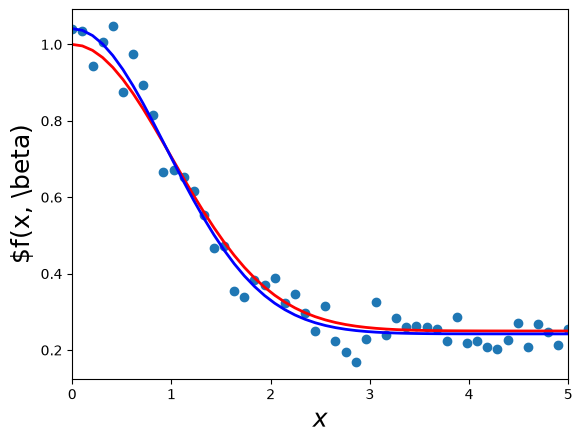

[0.         0.10204082 0.20408163 0.30612245 0.40816327 0.51020408
 0.6122449  0.71428571 0.81632653 0.91836735 1.02040816 1.12244898
 1.2244898  1.32653061 1.42857143 1.53061224 1.63265306 1.73469388
 1.83673469 1.93877551 2.04081633 2.14285714 2.24489796 2.34693878
 2.44897959 2.55102041 2.65306122 2.75510204 2.85714286 2.95918367
 3.06122449 3.16326531 3.26530612 3.36734694 3.46938776 3.57142857
 3.67346939 3.7755102  3.87755102 3.97959184 4.08163265 4.18367347
 4.28571429 4.3877551  4.48979592 4.59183673 4.69387755 4.79591837
 4.89795918 5.        ]
[1.03998823 1.03611558 0.94259153 1.00518617 1.04815965 0.87463294
 0.97451426 0.89324603 0.81629943 0.66729187 0.67064305 0.65282331
 0.6153252  0.55396683 0.46844067 0.47201153 0.35376294 0.33954543
 0.38211859 0.37086376 0.38854316 0.32216873 0.34607618 0.29711913
 0.25101492 0.31596752 0.22329004 0.19569662 0.16871269 0.22830081
 0.32590428 0.2396731  0.28273473 0.26115835 0.26231835 0.26107915
 0.25566816 0.22486172 0.28726193 0.21

In [43]:
#Добавим шума в данные, сделанные по функции f(x,b) с коэффицентоами b = (0.25, 0.75, 0.5)
beta = (0.25, 0.75, 0.5)
def f(x, b0, b1, b2):
    return b0 + b1 * np.exp(-b2 * x **2)
xdata = np.linspace(0, 5, 50)
y = f(xdata, *beta)
# зашушмляем эти данные
ydata = y + 0.05 * np.random.randn(len(xdata))
# Используем функцию для получение в виде коэффицентов функции f(x) для указанным xdata и ydata
import scipy as sp
from scipy.optimize import curve_fit

beta_opt, beta_cov = sp.optimize.curve_fit(f, xdata, ydata)
beta_opt
# Вычислим линейное отклонение
lin_dev = sum(beta_cov[0])
print(lin_dev)

# Вычисляем квадратичное отклонение
residuals = ydata - f(xdata, *beta_opt)
fres = sum(residuals**2)
print(fres)

fig, ax = plt.subplots()
ax.scatter(xdata, ydata)
ax.plot(xdata, y, 'r', lw=2)
ax.plot(xdata, f(xdata, *beta_opt), 'b', lw=2)
ax.set_xlim(0, 5)
ax.set_xlabel(r"$x$", fontsize=18)
ax.set_ylabel(r"$f(x, \beta)", fontsize=18)
plt.show()
print(xdata)
print(ydata)

### 1.1.5 Пример
***Задача:*** Необходимо проверить гипотезу, что наши точечно заданная функция ложится на кривые вида:
1) $ f(x,b) = b_0 + b_1x $
2) $ f(x,b) = b_0 + b_1x + b_2x^2 $
3) $ f(x,b) = b_0 + b_1ln(x) $
4) $f(x, b) = b_0 x^{b_1}$


[0.25243015 0.74935169]
0.000143886071657686
286.83322234783003


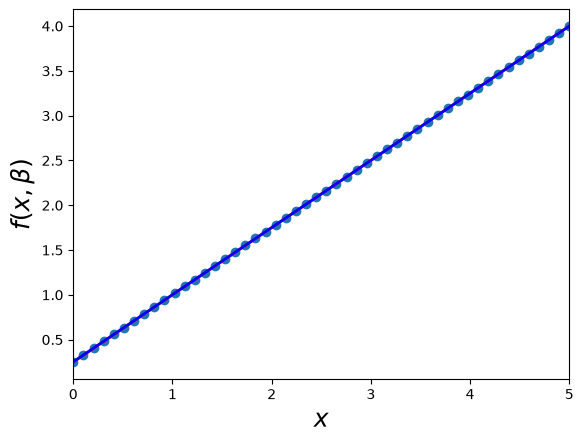

In [44]:
#решение
#1
#Добавим шума в данные, сделанные по функции f(x,b) с коэффицентами b = (0.25, 0.75)
beta = (0.25, 0.75)
def f(x, b0, b1):
    return b0 + b1 * x
# зададим массивы точке xi
xdata = np.linspace(0, 5, 50)
y = f(xdata, *beta)
# зашумляем эти данные
ydata = y + 0.05 * np.random.randn(len(xdata))
beta_opt,beta_cov = sp.optimize.curve_fit(f, xdata, ydata)
print(beta_opt)
# вычислим линейное отклонение
lin_dev = sum(beta_cov[0])
print(lin_dev)

# вычислим квадратичное отклонение
residuals = ydata = f(xdata,*beta_opt)
fres = sum(residuals**2)
print(fres)

fig, ax = plt.subplots()
ax.scatter(xdata, ydata)
ax.plot(xdata, y, 'r', lw=2)
ax.plot(xdata, f(xdata, *beta_opt), 'b', lw=2)
ax.set_xlim(0, 5)
ax.set_xlabel(r"$x$", fontsize=18)
ax.set_ylabel(r"$f(x, \beta)$", fontsize=18)
plt.show()

***Задание:*** 
Подставьте собственные данные и поэкспериментируйте с представленный функциями. Проанализируйте динамику изменения данные. 
***Решение:*** Рассмотрим функцию экспоненциальной регресии.
$$ f(x) = b_0 e^{b_1 x} $$

Линейная: b0 + b1*x:
  истинные:  (0.25, 0.75)
  найденные: (np.float64(0.2454), np.float64(0.7515))
  RSS = 0.1159

Квадратичная: b0 + b1*x + b2*x²:
  истинные:  (0.25, 0.75, 0.5)
  найденные: (np.float64(0.2638), np.float64(0.7466), np.float64(0.5009))
  RSS = 0.1214

Логоримфическая: b0 + b1_ln(x):
  истинные:  (1.0, 2.0)
  найденные: (np.float64(1.015), np.float64(1.9766))
  RSS = 0.0870

Степенная: b0·x^b1:
  истинные:  (1.0, 2.0)
  найденные: (np.float64(1.0021), np.float64(1.9989))
  RSS = 0.1245

Экспоненциальная: b0·exp(b1·x):
  истинные:  (1.0, 0.5)
  найденные: (np.float64(1.0016), np.float64(0.4993))
  RSS = 0.1536



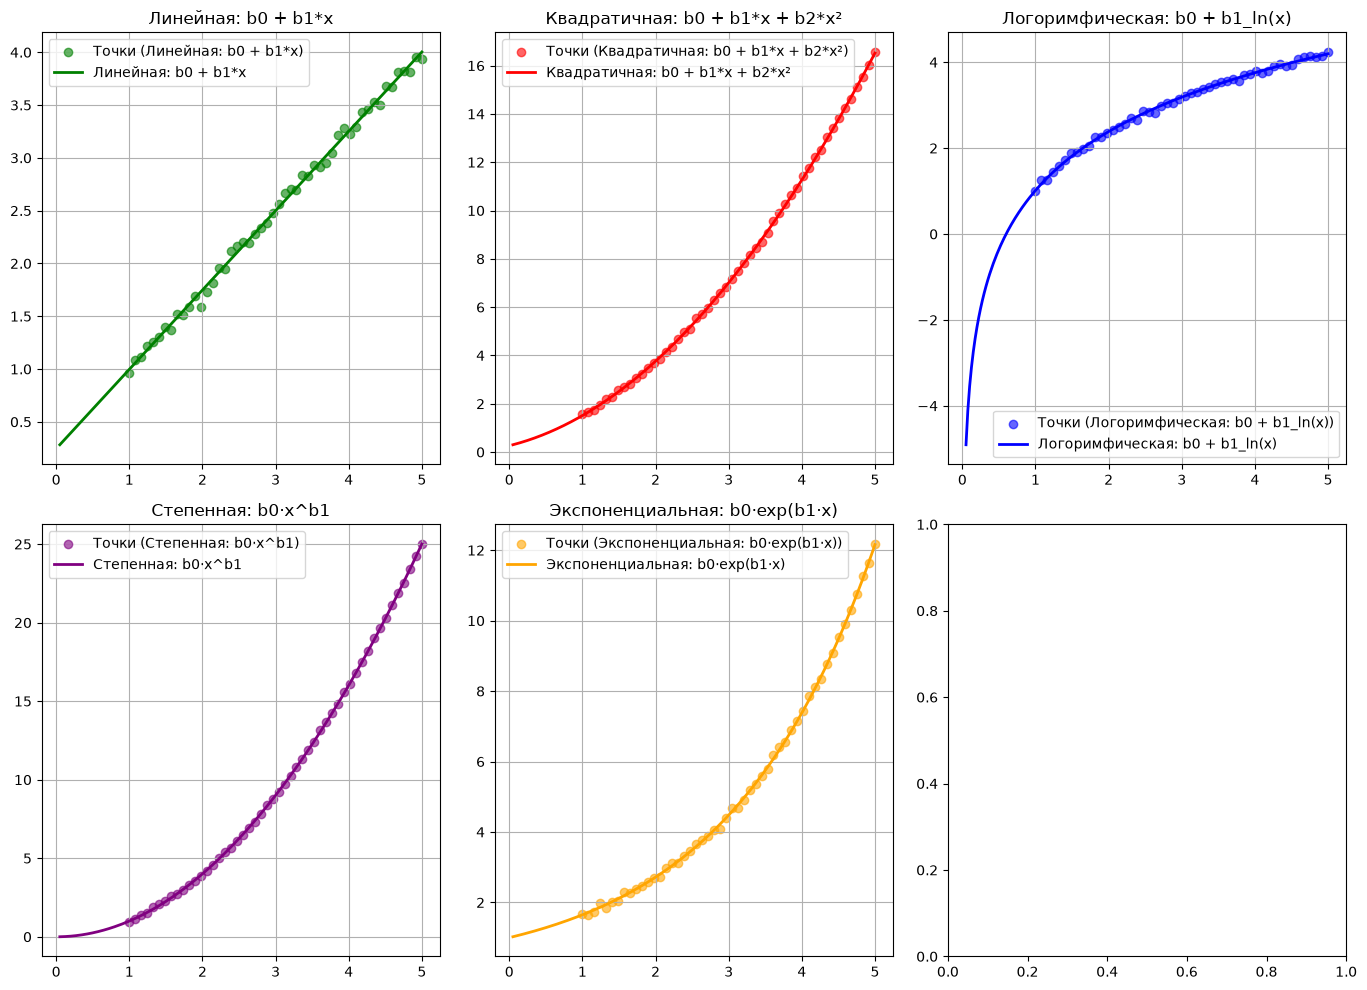

In [45]:
### Решение через ООП 
# общая логика: обучение, расчет ошибки, составления графика
class BaseFitter:
    # Добавьте color='blue' сюда, в скобки:
    def __init__(self, name, color, beta_true):
        self.name = name
        self.color = color
        self.beta_true = beta_true
        self.beta_opt = None
        self.beta_cov = None

    @staticmethod
    def formula(x, *beta):
        raise NotImplementedError("Нужно определить формулу в дочернем классе")

    def generate_data(self, N=50, noise=0.05, x_range=(1, 5), seed=42):
       x = np.linspace(*x_range, N)
       y_clean = self.formula(x, *self.beta_true)
       y = y_clean + noise * np.random.randn(len(x))
       return x, y 

    def fit(self, xdata, ydata):
        self.beta_opt, self.beta_cov = curve_fit(self.formula, xdata, ydata)

    # Метод предсказания значений Y для любых новых X
    def predict(self, x):
        if self.beta_opt is None:
            raise ValueError('Сначала обучите модель методом fit()')
        return self.formula(x, *self.beta_opt)

    # Метод вычисления квадратичного отклонения (RSS)
    def get_squared_error(self, xdata, ydata):
        residuals = ydata - self.predict(xdata)
        return np.sum(residuals**2)

     # Метод отрисовки кривой
    def plot_data(self, ax, xdata, ydata):
        ax.scatter(
            xdata, ydata, color=self.color, alpha=0.6, label=f'Точки ({self.name})'
        )

    def plot_curve(self, ax, x_range):
        y_pred = self.predict(x_range)
        ax.plot(x_range, y_pred, color=self.color, lw=2, label=self.name)

# 1) Линейная:  f(x) = b0 + b1·x
class LinearModel(BaseFitter):
  def __init__(self):
    super().__init__(name='Линейная: b0 + b1*x', color="green", beta_true=(0.25, 0.75))

  @staticmethod
  def formula(x, b0, b1):
    return b0 + b1 * x

# 2) Квадратичная:  f(x) = b0 + b1·x + b2·x²
class QuadraticModel(BaseFitter):
  def __init__(self):
    super().__init__(name='Квадратичная: b0 + b1*x + b2*x²', color='red', beta_true=(0.25, 0.75, 0.5))

  @staticmethod
  def formula(x, b0, b1, b2):
    return b0 + b1 * x + b2 * x**2

# 3) Логарифмическая:  f(x) = b0 + b1·ln(x)
class LogorithmicModel(BaseFitter):
    def __init__(self):
        super().__init__(name='Логоримфическая: b0 + b1_ln(x)', color='blue', beta_true=(1.0, 2.0))

    @staticmethod
    def formula(x, b0, b1):
        return b0 + b1 * np.log(x)


# 4) Степенная:  f(x) = b0·x^b1
class PowerModel(BaseFitter):
    def __init__(self):
      super().__init__(name='Степенная: b0·x^b1', color='purple', beta_true=(1.0, 2.0))
    
    @staticmethod
    def formula(x, b0, b1):
       return b0 * x ** b1

# 5) Экспоненциальная: f(x) = b0·e^(b1*x)
class ExponentialModel(BaseFitter):
    def __init__(self):
        super().__init__(name='Экспоненциальная: b0·exp(b1·x)', color='orange', beta_true=(1.0, 0.5))

    @staticmethod
    def formula(x, b0, b1):
        return b0 * np.exp(b1 * x)

if __name__ == '__main__':

    models = [LinearModel(), QuadraticModel(), LogorithmicModel(), PowerModel(), ExponentialModel()]

    datasets = [m.generate_data(N=50, noise=0.05) for m in models]

    # Обучение + вывод
    for model, (xd, yd) in zip(models, datasets):
        model.fit(xd, yd)
        print(f'{model.name}:')
        print(f'  истинные:  {model.beta_true}')
        print(f'  найденные: {tuple(np.round(model.beta_opt, 4))}')
        print(f'  RSS = {model.get_squared_error(xd, yd):.4f}\n')

    # Графики 2×2
    fig, axes = plt.subplots(2, 3, figsize=(14, 10))
    x_smooth = np.linspace(0.05, 5, 200)

    for ax, model, (xd, yd) in zip(axes.flatten(), models, datasets):
        model.plot_data(ax, xd, yd)
        model.plot_curve(ax, x_smooth)
        ax.set_title(model.name)
        ax.legend(); ax.grid(True)

    plt.tight_layout()
    plt.show()

***Вывод:*** экспоненциальная и степенная модели весьма близко похожи, но эсконенциальная модели "быстрее" ускоряется и растёт. 

## 1.2 Задачи регрессии
Линейная регрессия - это широко используемый метод статического анализа, который использует регрессионный анализ в математической статистике для определения колличественной взаимосвязи между двумя или более переменными. Если регресионный анализ включает две или более независимых переменных, а связь между зависимой и независимой переменными является лийнейной, тогда имеем дело с множественной линейной регресии.

### 1.2.1 Пример
***Задача:***
Построим простую линейную регрессию в Python с использованием библиотеки sckit-learn.

,Учебное время,Оценка
0,0.50,10
1,0.75,22
2,1.00,13
3,1.25,43
4,1.50,20


(20, 2)


,Учебное время,Оценка
count,20.000000,20.000000
mean,2.787500,53.700000
std,1.507165,26.435821
min,0.500000,10.000000
25%,1.687500,30.250000
50%,2.625000,58.500000
75%,4.062500,75.250000
max,5.500000,93.000000


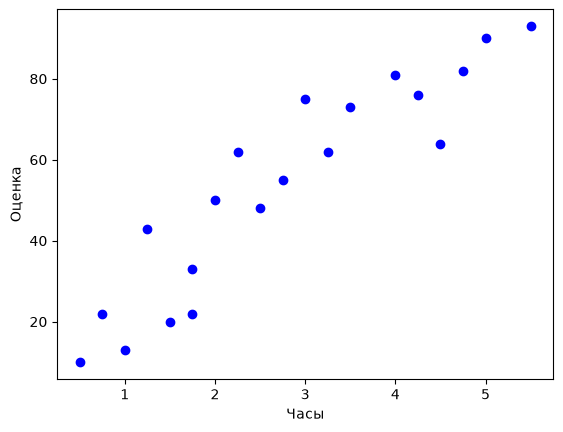

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas import DataFrame, Series 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

my_dict = {'Учебное время': [0.50,0.75,1.00,1.25,1.50,
                              1.75,1.75,2.00,2.25,
                              2.50,2.75,3.00,3.25,
                              3.50,4.00,4.25,4.50,
                              4.75,5.00,5.50],
            'Оценка': [10,22,13,43,20,22,33,50,62,48,55,75,62,73,81,76,64,82,90,93] }

dataset = pd.DataFrame(my_dict)
display(dataset.head())
print(dataset.shape)
display(dataset.describe())
plt.scatter(dataset['Учебное время'], dataset['Оценка'], color = 'b', label = 'данные экзамена')
plt.xlabel("Часы")
plt.ylabel("Оценка")
plt.show()

После того как мы получили представление о данных, разделим информацию на "атрибуты" и "метки". Атрибуты - это независимые переменные, а метки - это независимые переменные, значения которых должны быть предсказаны. В нашем наборе всего два столбца и необходимо предсказать в зависимости от количества часов. Чтобы извлечь атрибуты и метки, выполним следующий скрипт:

In [47]:
X = dataset.iloc[:, :-1].values
Y = dataset.iloc[:, 1].values
print(X)
print(Y)
# Теперь, когда у нас есть атрибуты и метки, необходимо разделить их на обучающий и тестовые набора
# Приведенный фрагмент разделяет 80% на обучающий набор, а 20% данных = на набор тестов
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=0)
regressor = LinearRegression()
regressor.fit(X_train, y_train)
# приведем получившиеся коэффиценты для линии регрессии
print(regressor.intercept_)
print(regressor.coef_)

[[0.5 ]
 [0.75]
 [1.  ]
 [1.25]
 [1.5 ]
 [1.75]
 [1.75]
 [2.  ]
 [2.25]
 [2.5 ]
 [2.75]
 [3.  ]
 [3.25]
 [3.5 ]
 [4.  ]
 [4.25]
 [4.5 ]
 [4.75]
 [5.  ]
 [5.5 ]]
[10 22 13 43 20 22 33 50 62 48 55 75 62 73 81 76 64 82 90 93]
5.475400029908791
[17.02706744]


Получившийся результат можно интерпретировать следующим образом: с каждым затраченным часом на обучение результат экзамена повышается приблизительно на 17 баллов. Далее можно построить прогноза. Для этого мы будем использовать наши тестовые данные и посмотрим, наскольк точно наш алгоритм предсказывает процентную оценку. Чтобы сделать прогноз на тестовых данные необходимо выполнить следующий код:

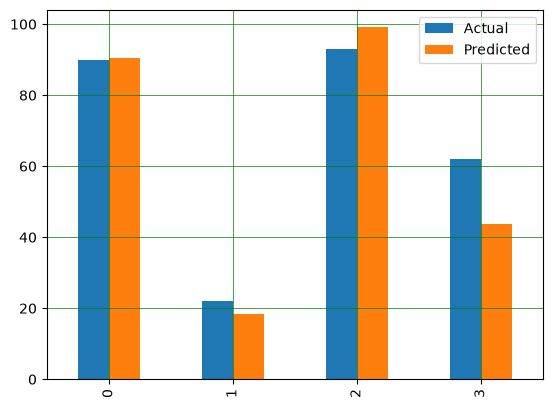

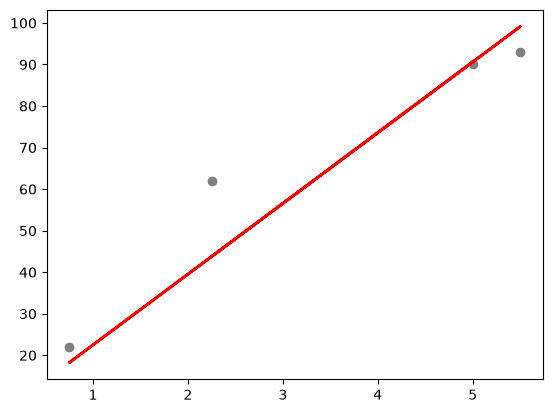

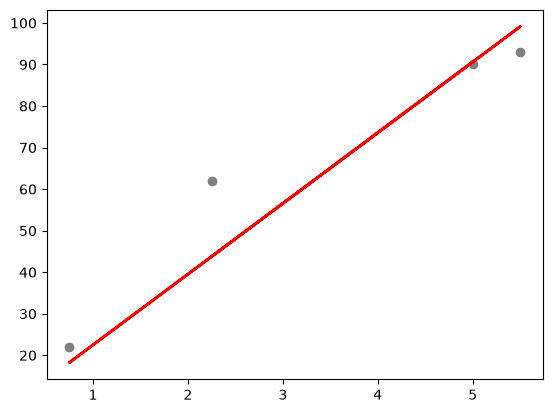

In [48]:
y_pred = regressor.predict(X_test)
# сравним фактические значения с прогнозируемыми
df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
df.plot(kind='bar')
plt.grid(which='major', linestyle='-', linewidth='0.5',color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()
plt.scatter(X_test, y_test, color='gray')
plt.plot(X_test, y_pred, color='red', linewidth=2)
plt.show(0)

***Задание:***
Постройте модель линейной регресии для произвольный данных из двух столбцов. Для примера можно взять точечную зависимость заработной платы опыта работы.
Найдите коэффиценты линии регресии. Постройте прогноз.

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


[[ 1.1]
 [ 1.3]
 [ 1.5]
 [ 2. ]
 [ 2.2]
 [ 2.9]
 [ 3. ]
 [ 3.2]
 [ 3.2]
 [ 3.7]
 [ 3.9]
 [ 4. ]
 [ 4. ]
 [ 4.1]
 [ 4.5]
 [ 4.9]
 [ 5.1]
 [ 5.3]
 [ 5.9]
 [ 6. ]
 [ 6.8]
 [ 7.1]
 [ 7.9]
 [ 8.2]
 [ 8.7]
 [ 9. ]
 [ 9.5]
 [ 9.6]
 [10.3]
 [10.5]]
[ 39343.  46205.  37731.  43525.  39891.  56642.  60150.  54445.  64445.
  57189.  63218.  55794.  56957.  57081.  61111.  67938.  66029.  83088.
  81363.  93940.  91738.  98273. 101302. 113812. 109431. 105582. 116969.
 112635. 122391. 121872.]
26780.09915062818
[9312.57512673]


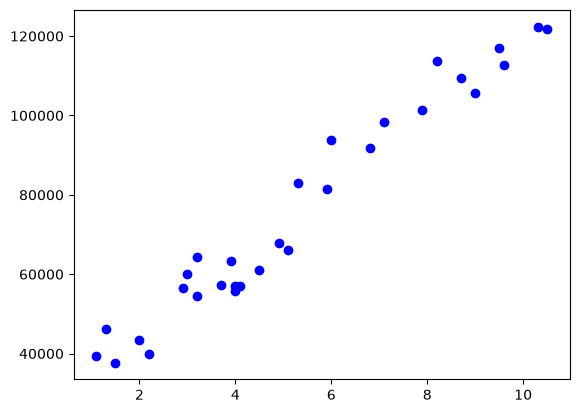

In [49]:
# Получим точечную диаграмму
dataset_task = pd.read_csv('https://raw.githubusercontent.com/AnnaShestova/salary-years-simple-linear-regression/master/Salary_Data.csv')
display(dataset_task.head(5))
display(dataset_task.describe())
#Нарисуем точечную диаграмму
plt.scatter(dataset_task['YearsExperience'], dataset_task['Salary'], color = 'b', label = 'Scalary Data')
X_salary = dataset_task.iloc[:, :-1].values
Y_salary = dataset_task.iloc[:, 1].values
print(X_salary)
print(Y_salary)
X_salary_train, X__salary_test, Y_salary_train, y_salary_test = train_test_split(X_salary,Y_salary, test_size=0.2, random_state=0)
regressor_salary = LinearRegression()
regressor_salary.fit(X_salary_train, Y_salary_train)
print(regressor_salary.intercept_)
print(regressor_salary.coef_)

Исходя изх результата, можно увидеть что заработная плата, с каждым годом получения опыта по должности, повышается примерно 9 тыс.

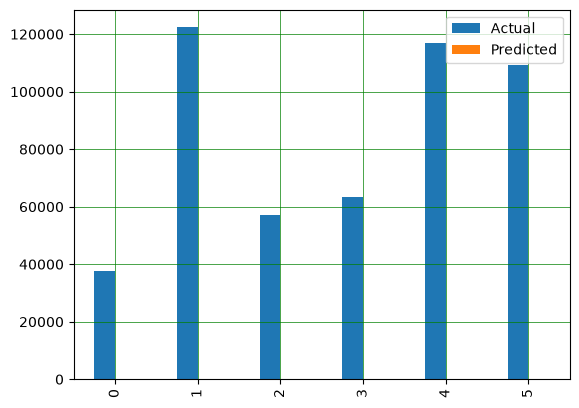

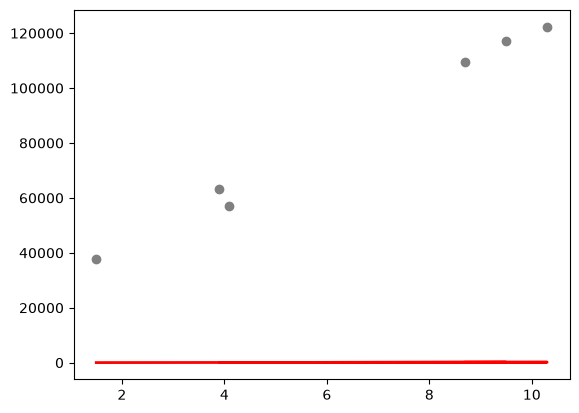

In [50]:
y_salary_pred = regressor.predict(X__salary_test)
df = pd.DataFrame({'Actual': y_salary_test, 'Predicted': y_salary_pred})
df.plot(kind='bar')
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

plt.scatter(X__salary_test, y_salary_test, color='gray')
plt.plot(X__salary_test, y_salary_pred, color='red', linewidth=2)
plt.show()


## 1.3 Множественная регрессия
В предыдущем примере мы проилюстрировали линейную регрессию с двумя переменными. Однако, почти все реальные задачи имеют больше параметров. Линейна регрессия с участием нескольких переменных называется "множественной линейной регрессией" или многомерной линейной регрессией. Шаги для выполнения множественной линейной регрессии аналогичны шагам для простой. Разница заключается в оценке. Вы можете использовать множественную регрессию, чтобы узнать, какой фактор оказывает наибольшее влияние на прогнозируемый результат или как различные переменные связаны друг с другом.

### 1.3.1 Пример
Задача: для решения задачи множественной регрессии задействовать уже известный метод numpy.linalg.lstsq

### 1.3.2 Пример
Задача: Для данных из предыдущей задачи построить модель множественной линейной регрессии с использованием средств библиотеки scikit-learn.


In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seabornInstance
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

y = np.array((1, 2, 3, 4, 3, 4, 5, 3, 5, 5, 4, 5, 4, 5, 4, 5, 6, 0, 6, 3, 1, 3, 1))

X = np.array((
    (0, 2, 4, 1, 5, 4, 5, 9, 9, 9, 3, 7, 8, 8, 6, 6, 5, 5, 5, 6, 6, 5, 5),
    (4, 1, 2, 3, 4, 5, 6, 7, 5, 8, 7, 8, 7, 8, 7, 8, 6, 8, 9, 2, 1, 5, 6),
    (4, 1, 2, 5, 6, 7, 8, 9, 7, 8, 7, 8, 7, 4, 3, 1, 2, 3, 4, 1, 3, 9, 7)
))

df1 = pd.DataFrame(np.array(y).transpose()).rename(columns = {0: 'y'}, inplace=False)
df2 = pd.DataFrame(np.array(X).transpose()).rename(columns={0: 'x1', 1: 'x2', 2: 'x3'}, inplace=False)
frames = [df1, df2]
dataset = pd.concat([df1,df2], axis=1, join="inner")
display(dataset.head())
display(dataset.shape)
display(dataset.describe())

X = dataset[['x1','x2','x3']]
y = dataset['y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
regressor = LinearRegression()
regressor.fit(X_train, y_train)
coeff_df = pd.DataFrame(regressor.coef_, X.columns, columns=['Coefficient'])
coeff_df
# прогнозы на тестовых данных
y_pred = regressor.predict(X_test)
df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
df
print('Mean Squared Error:', metrics.mean_absolute_error(y_test, y_pred))

/tmp/ipykernel_42371/393315307.py:17: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df1 = pd.DataFrame(np.array(y).transpose()).rename(columns = {0: 'y'}, inplace=False)
/tmp/ipykernel_42371/393315307.py:18: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df2 = pd.DataFrame(np.array(X).transpose()).rename(columns={0: 'x1', 1: 'x2', 2: 'x3'}, inplace=False)


,y,x1,x2,x3
0,1,0,4,4
1,2,2,1,1
2,3,4,2,2
3,4,1,3,5
4,3,5,4,6


(23, 4)

,y,x1,x2,x3
count,23.000000,23.000000,23.000000,23.000000
mean,3.565217,5.347826,5.521739,5.043478
std,1.674029,2.404706,2.428422,2.704849
min,0.000000,0.000000,1.000000,1.000000
25%,3.000000,4.500000,4.000000,3.000000
50%,4.000000,5.000000,6.000000,5.000000
75%,5.000000,6.500000,7.500000,7.000000
max,6.000000,9.000000,9.000000,9.000000


Mean Squared Error: 0.8524882178272476


### ***Задание***
Задача: Постройте модель множественной регрессии для произвольных данных из нескольких столбцов. Для примера можно взять потребления газа (в миллионых галлонов) в 48 штатах США или набор данных о качестве краскного вина. Найдите коэффиценты множественной регрессии. Постройте прогноз. 

In [52]:
dataset_multiple = pd.read_csv('https://raw.githubusercontent.com/likarajo/petrol_consumption/master/data/petrol_consumption.csv')
display(dataset_multiple.head(5))
display(dataset_multiple.shape)
display(dataset_multiple.describe())
X_multiple = dataset_multiple[['Average_income', 'Paved_Highways', 'Population_Driver_licence(%)', 'Petrol_Consumption']]
Y_multiple = dataset_multiple['Petrol_tax']

X_train_multiple, X_test_multiple, Y_train_multiple, Y_test_multiple = train_test_split(X_multiple, Y_multiple, test_size=0.2,random_state=0)
regressor_multiple = LinearRegression().fit(X_train_multiple, Y_train_multiple)
coeff_df_multiple = regressor_multiple.predict(X_test_multiple)
y_pred_multiply = regressor_multiple.predict(X_test_multiple)
df_multiple = pd.DataFrame({'Actual': Y_test_multiple, 'Predicted': y_pred_multiply})
display(df_multiple)
# Оцениваем производительность алгоритма вычисляя MSE
print('Mean Squared Error:', metrics.mean_squared_error(Y_test_multiple,y_pred_multiply))


,Petrol_tax,Average_income,Paved_Highways,Population_Driver_licence(%),Petrol_Consumption
0,9.0,3571,1976,0.525,541
1,9.0,4092,1250,0.572,524
2,9.0,3865,1586,0.580,561
3,7.5,4870,2351,0.529,414
4,8.0,4399,431,0.544,410


(48, 5)

,Petrol_tax,Average_income,Paved_Highways,Population_Driver_licence(%),Petrol_Consumption
count,48.000000,48.000000,48.000000,48.000000,48.000000
mean,7.668333,4241.833333,5565.416667,0.570333,576.770833
std,0.950770,573.623768,3491.507166,0.055470,111.885816
min,5.000000,3063.000000,431.000000,0.451000,344.000000
25%,7.000000,3739.000000,3110.250000,0.529750,509.500000
50%,7.500000,4298.000000,4735.500000,0.564500,568.500000
75%,8.125000,4578.750000,7156.000000,0.595250,632.750000
max,10.000000,5342.000000,17782.000000,0.724000,968.000000


,Actual,Predicted
29,9.0,7.962130
4,8.0,9.252421
26,8.0,7.763302
30,7.0,7.481077
32,8.0,7.696914
37,7.0,7.003346
34,8.0,8.370428
40,7.0,7.885720
7,8.0,8.646102
10,8.0,7.527290


Mean Squared Error: 0.45876860974833616


### **Задание**
***Задача:*** Экспериментально получены N - значений величины Y при различных значениях величины X. Построить полиномы первой и второй степени, апроксимирующие результаты эксперимента, с применением метода нахождения наименьших квадратов. Результаты выводятся в виде таблиц, значений и графиков, полученных полиномов.

Вариант 2

| x | y |
| :---: | :---: |
| 4,0 | 4,0 |
| 4,2 | 3,0 |
| 4,4 | 6,0 |
| 4,6 | 6,0 |
| 4,8 | 4,0 |
| 5,0 | 4,0 |


 Y (эксп.)  Y (ex)  Y (1я степ.)  Y (2я степ.)  Ошибка (1-я степ.)  Ошибка (2-я степ.)
       4.0     4.0         4.286         3.393              -0.286               0.607
       4.2     3.0         4.371         4.550              -1.371              -1.550
       4.4     6.0         4.457         5.171               1.543               0.829
       4.6     6.0         4.543         5.257               1.457               0.743
       4.8     4.0         4.629         4.807              -0.629              -0.807
       5.0     4.0         4.714         3.821              -0.714               0.179
Полином 1й степени: y = 2.5714 + 0.4286 * x
Полином 2й степени: y = 60.6964 + -6.6964 * x


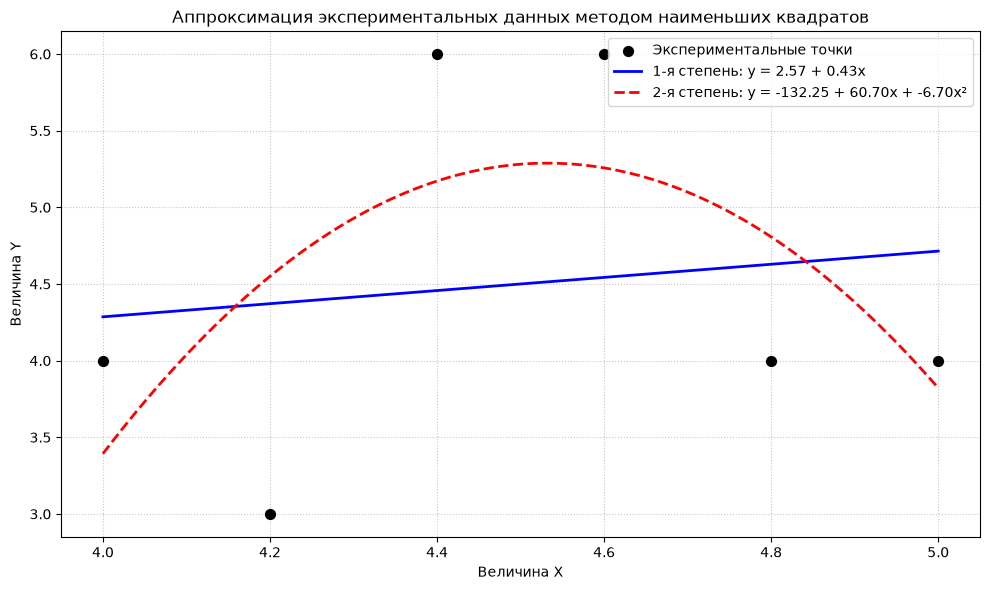


Сумма квадратов ошибок (RSS):
1-я степень: 7.3714
2-я степень: 4.6929 (чем меньше, тем лучше)


In [56]:
x = np.array([4.0, 4.2, 4.4, 4.6, 4.8, 5.0])
y = np.array([4.0, 3.0, 6.0, 6.0, 4.0, 4.0])

coeffs_1 = np.polyfit(x, y, 1)
coeffs_2 = np.polyfit(x, y, 2)

y_pred_1 = np.polyval(coeffs_1, x)
y_pred_2 = np.polyval(coeffs_2, x)

df = pd.DataFrame({
    'Y (эксп.)': x,
    'Y (ex)': y,
    'Y (1я степ.)': np.round(y_pred_1, 3),
    'Y (2я степ.)': np.round(y_pred_2, 3),
    'Ошибка (1-я степ.)': np.round(y-y_pred_1,3),
    'Ошибка (2-я степ.)': np.round(y-y_pred_2,3)
})

print(df.to_string(index=False))
print(f"Полином 1й степени: y = {coeffs_1[1]:.4f} + {coeffs_1[0]:.4f} * x")
print(f"Полином 2й степени: y = {coeffs_2[1]:.4f} + {coeffs_2[0]:.4f} * x")

x_smooth = np.linspace(np.min(x), np.max(x), 100)
y_smooth_1 = np.polyval(coeffs_1, x_smooth)
y_smooth_2 = np.polyval(coeffs_2, x_smooth)

plt.figure(figsize=(10, 6))

plt.scatter(x, y, color='black', s=50, zorder=5, label='Экспериментальные точки')

plt.plot(x_smooth, y_smooth_1, color='blue', linewidth=2, 
         label=f'1-я степень: y = {coeffs_1[1]:.2f} + {coeffs_1[0]:.2f}x')
plt.plot(x_smooth, y_smooth_2, color='red', linewidth=2, linestyle='--',
         label=f'2-я степень: y = {coeffs_2[2]:.2f} + {coeffs_2[1]:.2f}x + {coeffs_2[0]:.2f}x²')

plt.title('Аппроксимация экспериментальных данных методом наименьших квадратов')
plt.xlabel('Величина X')
plt.ylabel('Величина Y')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

rss_1 = np.sum((y - y_pred_1)**2)
rss_2 = np.sum((y - y_pred_2)**2)
print(f"\nСумма квадратов ошибок (RSS):")
print(f"1-я степень: {rss_1:.4f}")
print(f"2-я степень: {rss_2:.4f} (чем меньше, тем лучше)")


**Вывод:** 

На основе проведенного анализа методом наименьших квадратов можно сделать вывод, что полином второй степени формально лучше описывает экспериментальные данные, так как имеет меньшую сумму квадратов ошибок (RSS) и улавливает нелинейный характер зависимости (рост с последующим спадом). Однако из-за значительного разброса измерений при $ x=4.6 $ (значения 3.0, 4.0 и 6.0) линейная модель (первой степени) демонстрирует большую математическую устойчивость и меньше подвержена влиянию возможных выбросов или грубых погрешностей. Таким образом, окончательный выбор аппроксимирующей функции должен опираться на физический смысл исследуемого процесса, а для повышения достоверности результатов рекомендуется провести дополнительные контрольные измерения в области $ x∈[4.4;4.8] $